In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Un proyecto se programa con el método de la cadena crítica. Para cada actividad, su responsable ha dado una estimación **segura** (con la que cumpliría aproximadamente nueve de cada diez veces, el percentil 90) y una estimación **agresiva pero alcanzable** (la mediana, el percentil 50), ambas en días. Algunas actividades las ejecuta el mismo equipo (columna *recurso*); cada equipo sólo puede atender una actividad a la vez y, una vez empezada, no la interrumpe. Los conflictos de recursos se resuelven programando día a día: cuando varias actividades del mismo equipo pueden empezar, tiene prioridad la de menor inicio más tardío en el cronograma sin recursos (calculado con las estimaciones agresivas); a igualdad, la de menor duración y, después, la primera por orden alfabético. Los colchones se dimensionan por el método de cortar y pegar y se redondean al día superior.

In [4]:
pregunta_1 = "1. Sin tener en cuenta los equipos, calcule con las estimaciones agresivas la duración del proyecto y su ruta crítica. ¿Qué actividades de un mismo equipo se solapan?  "
pregunta_2 = "2. Resuelva los conflictos con la regla de prioridad indicada. ¿En qué orden atiende cada equipo a sus actividades? Añada esos enlaces de recurso a la red y calcule la duración del proyecto con los equipos.  "
pregunta_3 = "3. Identifique la cadena crítica: sus actividades y si cada enlace entre ellas es de precedencia o de recurso. ¿Coincide con la ruta crítica del apartado 1? ¿Por qué?  "
pregunta_4 = "4. Dimensione el colchón del proyecto y dé la fecha comprometida. ¿Antes de qué actividades de la cadena colocaría colchones de recursos y en qué consisten?  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Sin tener en cuenta los equipos, calcule con las estimaciones agresivas la duración del proyecto y su ruta crítica. ¿Qué actividades de un mismo equipo se solapan?  

2. Resuelva los conflictos con la regla de prioridad indicada. ¿En qué orden atiende cada equipo a sus actividades? Añada esos enlaces de recurso a la red y calcule la duración del proyecto con los equipos.  

3. Identifique la cadena crítica: sus actividades y si cada enlace entre ellas es de precedencia o de recurso. ¿Coincide con la ruta crítica del apartado 1? ¿Por qué?  

4. Dimensione el colchón del proyecto y dé la fecha comprometida. ¿Antes de qué actividades de la cadena colocaría colchones de recursos y en qué consisten?  

In [5]:
#| tbl-cap: "Cuadro de datos del enunciado (días)"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, agresiva, segura, recurso
    ('A'     , '---'      , 4       , 6     , '---'  ),
    ('B'     , '---'      , 6       , 9     , 'Y'    ),
    ('C'     , '---'      , 2       , 3     , '---'  ),
    ('D'     , 'B,C'      , 6       , 9     , '---'  ),
    ('E'     , 'A,D'      , 9       , 11    , 'X'    ),
    ('F'     , 'E'        , 2       , 3     , 'X'    ),
    ('G'     , 'D'        , 6       , 9     , 'X'    ),
    ('H'     , 'D'        , 4       , 6     , 'Y'    ),
    ('I'     , 'F,G,H'    , 6       , 9     , '---'  ),
], columns=['activity', 'predecessor', 'agresiva', 'segura', 'recurso']).set_index('activity')
datos_enunciado

,predecessor,agresiva,segura,recurso
activity,,,,
A,---,4,6,---
B,---,6,9,Y
C,---,2,3,---
D,"B,C",6,9,---
E,"A,D",9,11,X
F,E,2,3,X
G,D,6,9,X
H,D,4,6,Y
I,"F,G,H",6,9,---


# Resolución

In [6]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
METODO = 'cortar_pegar'
equipos = sorted(set(datos_proyecto['recurso']) - {'---'})
datos_proyecto['equipo'] = datos_proyecto['recurso'].replace('---', '')
datos_proyecto['duration'] = datos_proyecto['agresiva']

In [7]:
# Funciones auxiliares de la cadena crítica: cálculos intermedios con los números sustituidos
from math import ceil, sqrt
from pmule import grafico_fiebre_tikz
pd.set_option('display.max_colwidth', None)
GANTT_CC = dict(GANTT_PARAMS, period_width=0.6, activity_inner_text_style=r'\bfseries\small')


def sin_decimales(tabla):
    """Números enteros sin «.0» al mostrar una tabla."""
    return tabla.map(lambda v: f'{v:g}' if isinstance(v, float) else v)


def tabla_margenes(datos, actividades):
    """Margen retirado (segura − agresiva) de cada actividad."""
    t = datos.loc[list(actividades), ['segura', 'agresiva']].copy()
    t['margen = segura − agresiva'] = [f'{s} − {a} = {s - a}' for s, a in zip(t['segura'], t['agresiva'])]
    return t.T


def detalle_colchon(margenes, nombre='colchón'):
    """Colchón por cortar y pegar y por la raíz de la suma de cuadrados (redondeo al día superior)."""
    ms = [int(m) for m in margenes]
    suma, cuad = sum(ms), sum(m * m for m in ms)
    cp, rz = 0.5 * suma, sqrt(cuad)
    return pd.DataFrame({nombre: {
        'cortar y pegar = 0,5·Σ márgenes': f"0,5·({' + '.join(map(str, ms))}) = 0,5·{suma} = {cp:g} → {ceil(cp - 1e-9)}",
        'raíz = √(Σ márgenes²)': f"√({' + '.join(f'{m}²' for m in ms)}) = √{cuad} = {rz:.2f} → {ceil(rz - 1e-9)}"}})


def tabla_alimentacion(plan):
    """Colchones de alimentación: arco en el que desemboca la cadena de alimentación, colchón
    requerido, holgura disponible y colchón adoptado."""
    filas = {}
    for nombre, fila in plan.alimentacion.iterrows():
        ms = [int(x) for x in str(fila['margenes']).split(' + ')]
        if plan.metodo_alimentacion == 'cortar_pegar':
            calc = f"0,5·({' + '.join(map(str, ms))}) = {0.5 * sum(ms):g} → {int(fila['requerido'])}"
        else:
            calc = f"√({' + '.join(f'{m}²' for m in ms)}) = {sqrt(sum(m * m for m in ms)):.2f} → {int(fila['requerido'])}"
        entrada = int(plan.inicio_temprano[fila['antes_de']]) if fila['antes_de'] != 'fin' else int(plan.duracion_cadena)
        fin_p = int(plan.inicio_temprano[fila['desde']] + plan.agresiva[fila['desde']])
        filas[nombre] = {'arco': f"{fila['desde']} → {fila['antes_de']}",
                         'cadena de alimentación': fila['cadena_alimentacion'],
                         'colchón requerido': calc,
                         'holgura disponible = inicio de la cadena − fin más temprano': f"{entrada} − {fin_p} = {int(fila['disponible'])}",
                         'colchón adoptado = mín(requerido, disponible)': int(fila['adoptado'])}
    return pd.DataFrame(filas).T


def detalle_alap(plan):
    """Programación lo más tarde posible de las actividades de alimentación (de la última a la primera)."""
    cadena = set(plan.cadena)
    ca = {(fila['desde'], fila['antes_de']): (n, int(fila['adoptado'])) for n, fila in plan.alimentacion.iterrows()}
    suc = {a: sorted(b for b in plan.predecesoras if a in plan.predecesoras[b]) for a in plan.predecesoras}
    filas = {}
    for a in reversed(plan.orden):
        if a in cadena:
            continue
        cands = []
        for b in suc[a]:
            if b in cadena:
                n, fb = ca[(a, b)]
                cands.append(f'{b} − {n}: {int(plan.inicios[b])} − {fb} = {int(plan.inicios[b]) - fb}')
            else:
                cands.append(f'{b}: {int(plan.inicios[b])}')
        if not suc[a]:
            n, fb = ca[(a, 'fin')]
            cands.append(f'fin − {n}: {plan.duracion_cadena} − {fb} = {plan.duracion_cadena - fb}')
        fin = int(plan.inicios[a] + plan.agresiva[a])
        filas[a] = {'fin = mín(inicio de las sucesoras)': f"mín({'; '.join(cands)}) = {fin}",
                    'inicio = fin − duración': f'{fin} − {int(plan.agresiva[a])} = {int(plan.inicios[a])}',
                    'inicio más temprano': int(plan.inicio_temprano[a])}
    return pd.DataFrame(filas).T


def resumen_informes(plan, informes):
    """Cálculos de cada informe de avance con los números sustituidos."""
    T, CP = plan.duracion_cadena, plan.colchon_proyecto
    columnas = {}
    for inf in informes:
        det = inf['detalle']
        curso = det[det['estado'] == 'en curso']
        pend = det[det['estado'] == 'pendiente']
        partes = [f"{r:g} ({a})" for a, r in curso['restante'].items()] + [f"{int(d)} ({a})" for a, d in pend['agresiva'].items()]
        restante = float(det['restante'].sum())
        pa, pc = inf['pct_avance'], inf['pct_consumo']
        columnas[f"día {inf['dia']}"] = {
            'fin previsto = día + restante de la cadena': f"{inf['dia']} + {' + '.join(partes) if partes else '0'} = {inf['fin_previsto']:g}",
            'colchón consumido': f"{inf['fin_previsto']:g} − {T} = {inf['consumo']:g} días → {inf['consumo']:g}/{CP} = {pc:.1f} %",
            'cadena completada': f"({T} − {restante:g})/{T} = {pa:.1f} %",
            'BPI = % colchón restante / % cadena restante': (f"(100 − {pc:.1f})/(100 − {pa:.1f}) = {inf['bpi']:.2f}" if pa < 100 else '—'),
            'límite verde = 10 + 0,6·avance': f"10 + 0,6·{pa:.1f} = {inf['limite_verde']:.1f} %",
            'límite rojo = 30 + 0,6·avance': f"30 + 0,6·{pa:.1f} = {inf['limite_roja']:.1f} %",
            'zona': inf['zona']}
    return pd.DataFrame(columnas)


def solapes(calendario, datos):
    """Pares de actividades del mismo equipo que se solapan en el cronograma sin recursos."""
    filas = []
    for equipo, grupo in datos[datos['recurso'] != '---'].groupby('recurso'):
        acts = sorted(grupo.index)
        for i, a in enumerate(acts):
            for b in acts[i + 1:]:
                ia = (int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano']))
                ib = (int(calendario.loc[b, 'inicio_mas_temprano']), int(calendario.loc[b, 'fin_mas_temprano']))
                solape = min(ia[1], ib[1]) - max(ia[0], ib[0])
                if solape > 0:
                    filas.append({'equipo': equipo, 'actividades': f'{a} y {b}',
                                  'intervalos': f'{a} [{ia[0]}, {ia[1]}) y {b} [{ib[0]}, {ib[1]})', 'días de solape': solape})
    return pd.DataFrame(filas, columns=['equipo', 'actividades', 'intervalos', 'días de solape']).rename(index=lambda i: i + 1)


def esperas_por_recurso(asignacion):
    """Actividades que esperan a un equipo: desde cuándo están listas, cuándo empiezan y quién las bloquea."""
    t = asignacion.traza
    esp = t[t['decision'] == 'espera']
    filas = {}
    for a, g in esp.groupby('actividad'):
        filas[a] = {'lista desde el día': int(g['periodo'].min()) - 1, 'empieza el día': int(asignacion.inicios[a]),
                    'espera (días)': int(asignacion.inicios[a]) - int(g['periodo'].min()) + 1,
                    'equipo que la bloquea': ', '.join(sorted(set(g['bloqueada_por'])))}
    return pd.DataFrame(filas).T

## Apartado 1

In [8]:
display(Markdown(pregunta_1))

1. Sin tener en cuenta los equipos, calcule con las estimaciones agresivas la duración del proyecto y su ruta crítica. ¿Qué actividades de un mismo equipo se solapan?  

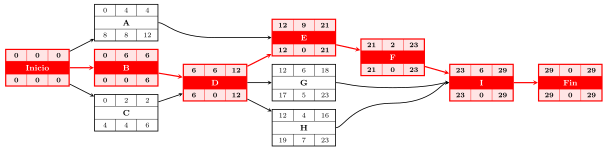

In [9]:
#| fig-cap: "Grafo Roy con las estimaciones agresivas, sin tener en cuenta los equipos"
#| label: fig-pert
proyecto.roy(durations=datos_proyecto['duration'], ranksep=1.2, nodesep=1.2)

Cálculo de los tiempos mínimos y máximos de los nodos del grafo Roy paso a paso (avance con los botones):

In [10]:
proyecto.display_roy_pasos(datos_proyecto['duration'])

In [11]:
#| tbl-cap: "Calendario sin tener en cuenta los equipos (estimaciones agresivas)"
#| label: tbl-calendario
calendario = proyecto.calendar(datos_proyecto['duration'])
proyecto.display_calendario(datos_proyecto['duration'], grafo="roy")

Actividad,Duración,Inicio más temprano,Fin más temprano,Inicio más tardío,Fin más tardío,H total,H libre,H independiente
A,4,0,4,8,12,8,8,8
B,6,0,6,0,6,0,0,0
C,2,0,2,4,6,4,4,4
D,6,6,12,6,12,0,0,0
E,9,12,21,12,21,0,0,0
F,2,21,23,21,23,0,0,0
G,6,12,18,17,23,5,5,5
H,4,12,16,19,23,7,7,7
I,6,23,29,23,29,0,0,0


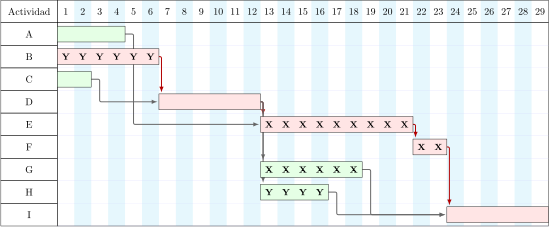

In [12]:
#| fig-cap: "Gantt de inicios más tempranos sin tener en cuenta los equipos (en cada barra, el equipo)"
#| label: fig-ganttLibre
_, dibujo = proyecto.gantt(datos_proyecto, 'duration', 'equipo', tikz=True, params=GANTT_CC)
pinta_tikz(dibujo)

In [13]:
#| tbl-cap: "Actividades de un mismo equipo que se solapan"
#| label: tbl-solapes
solapes(calendario, datos_proyecto)

,equipo,actividades,intervalos,días de solape
1,X,E y G,"E [12, 21) y G [12, 18)",6


In [14]:
T_libre = int(calendario['fin_mas_temprano'].max())
ruta_libre = [a for a in calendario.index if calendario.loc[a, 'H_total'] == 0]
Markdown(f'Sin tener en cuenta los equipos el proyecto dura {T_libre} días y su ruta crítica es {" - ".join(sorted(ruta_libre, key=lambda a: calendario.loc[a, "inicio_mas_temprano"]))}; '
         'pero el cronograma no es realizable: un equipo no puede hacer dos actividades a la vez.')

Sin tener en cuenta los equipos el proyecto dura 29 días y su ruta crítica es B - D - E - F - I; pero el cronograma no es realizable: un equipo no puede hacer dos actividades a la vez.

## Apartado 2

In [15]:
display(Markdown(pregunta_2))

2. Resuelva los conflictos con la regla de prioridad indicada. ¿En qué orden atiende cada equipo a sus actividades? Añada esos enlaces de recurso a la red y calcule la duración del proyecto con los equipos.  

Se programa día a día con un equipo de cada tipo (límite 1). La prioridad usa el inicio más tardío del calendario anterior. La tabla recoge las actividades que tienen que esperar a su equipo.

In [16]:
demanda = pd.DataFrame({e: (datos_proyecto['recurso'] == e).astype(int) for e in equipos})
demanda['duration'] = datos_proyecto['agresiva']
asignacion = proyecto.asignar_multi(demanda, 'duration', equipos, [1] * len(equipos), dibujar=False)
Markdown(f'Duración con los equipos: **{asignacion.duracion} días** (sin ellos, {T_libre}).')

Duración con los equipos: **35 días** (sin ellos, 29).

In [17]:
#| tbl-cap: "Esperas por falta de equipo"
#| label: tbl-esperas
esperas_por_recurso(asignacion)

,lista desde el día,empieza el día,espera (días),equipo que la bloquea
F,21,27,6,X
G,12,21,9,X


In [18]:
plan = proyecto.plan_cadena_critica(datos_proyecto, agresiva='agresiva', segura='segura', recurso='recurso', metodo=METODO)
pd.DataFrame({'orden en que atiende a sus actividades': {e: ' → '.join(plan.secuencias[e]) for e in equipos}})

,orden en que atiende a sus actividades
X,E → G → F
Y,B → H


In [19]:
#| tbl-cap: "Enlaces de recurso que se añaden a la red"
#| label: tbl-enlaces
plan.enlaces_recurso.rename(index=lambda i: i + 1)

,de,a,recurso
1,E,G,X
2,G,F,X


Cada enlace de recurso obliga a que una actividad empiece después de que termine la anterior del mismo equipo. Con ellos la red queda *nivelada*: cualquier programación que respete sus prelaciones respeta los equipos. (Los enlaces que ya están implícitos en las prelaciones no se añaden.)

In [20]:
red = plan.red_nivelada()
proyecto_nivelado = PredecessorTable.from_dataframe_of_strings(red, activity='activity', predecessor='predecessor').create_project()
red[['predecessor']].T

activity,A,B,C,D,E,F,G,H,I
predecessor,---,---,---,"B,C","A,D","E,G","D,E",D,"F,G,H"


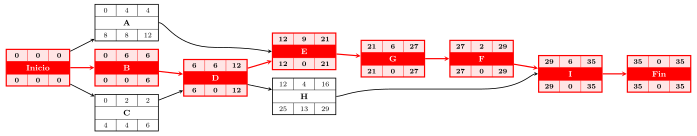

In [21]:
#| fig-cap: "Red nivelada (prelaciones y enlaces de recurso) con las estimaciones agresivas: su camino crítico es la cadena crítica"
#| label: fig-pertNivelado
proyecto_nivelado.roy(durations=red['agresiva'], ranksep=1.2, nodesep=1.2)

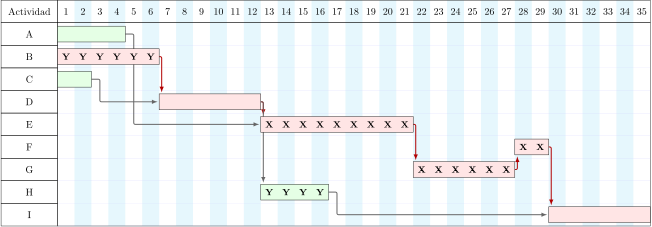

In [22]:
#| fig-cap: "Gantt de la red nivelada (inicios más tempranos)"
#| label: fig-ganttNivelado
_, dibujo = proyecto_nivelado.gantt(datos_proyecto.loc[red.index], 'duration', 'equipo', tikz=True, params=GANTT_CC)
pinta_tikz(dibujo)

## Apartado 3

In [23]:
display(Markdown(pregunta_3))

3. Identifique la cadena crítica: sus actividades y si cada enlace entre ellas es de precedencia o de recurso. ¿Coincide con la ruta crítica del apartado 1? ¿Por qué?  

In [24]:
#| tbl-cap: "Enlaces de la cadena crítica"
#| label: tbl-cadena
plan.enlaces_cadena.rename(index=lambda i: i + 1)

,de,a,motivo,recurso
1,B,D,precedencia,
2,D,E,precedencia,
3,E,G,recurso,X
4,G,F,recurso,X
5,F,I,precedencia,


In [25]:
Markdown(f'Cadena crítica: **{" - ".join(plan.cadena)}**, de {plan.duracion_cadena} días '
         f'({" + ".join(str(int(plan.agresiva[a])) for a in plan.cadena)}). No coincide con la ruta crítica sin recursos '
         f'({" - ".join(sorted(ruta_libre, key=lambda a: calendario.loc[a, "inicio_mas_temprano"]))}, {T_libre} días): '
         'la secuencia más larga pasa por un enlace de recurso, una dependencia que no está en el cuadro de prelaciones '
         'pero que existe porque el mismo equipo no puede hacer dos cosas a la vez. Por eso la cadena crítica se busca '
         'después de resolver los conflictos de recursos.')

Cadena crítica: **B - D - E - G - F - I**, de 35 días (6 + 6 + 9 + 6 + 2 + 6). No coincide con la ruta crítica sin recursos (B - D - E - F - I, 29 días): la secuencia más larga pasa por un enlace de recurso, una dependencia que no está en el cuadro de prelaciones pero que existe porque el mismo equipo no puede hacer dos cosas a la vez. Por eso la cadena crítica se busca después de resolver los conflictos de recursos.

## Apartado 4

In [26]:
display(Markdown(pregunta_4))

4. Dimensione el colchón del proyecto y dé la fecha comprometida. ¿Antes de qué actividades de la cadena colocaría colchones de recursos y en qué consisten?  

In [27]:
#| tbl-cap: "Colchón del proyecto"
#| label: tbl-colchon
detalle_colchon(plan.margen[plan.cadena], 'colchón del proyecto').loc[['cortar y pegar = 0,5·Σ márgenes']]

,colchón del proyecto
"cortar y pegar = 0,5·Σ márgenes","0,5·(3 + 3 + 2 + 3 + 1 + 3) = 0,5·15 = 7.5 → 8"


In [28]:
Markdown(f'Colchón del proyecto: **{plan.colchon_proyecto} días**; fecha comprometida {plan.duracion_cadena} + '
         f'{plan.colchon_proyecto} = **{plan.compromiso} días**.')

Colchón del proyecto: **8 días**; fecha comprometida 35 + 8 = **43 días**.

In [29]:
#| tbl-cap: "Colchones de recursos (avisos)"
#| label: tbl-avisos
plan.colchones_recursos.rename(columns={'antes_de': 'antes de', 'recursos': 'equipo al que se avisa', 'despues_de': 'mientras termina', 'inicio_previsto': 'inicio previsto'}).rename(index=lambda i: i + 1)

,antes de,equipo al que se avisa,mientras termina,inicio previsto
1,E,X,D,12


Un colchón de recursos no es tiempo en el cronograma: es un **aviso** al equipo que va a entrar en la cadena crítica, unos días antes de que termine la actividad anterior, para que esté libre y preparado en cuanto reciba el testigo. Se pone antes de cada actividad de la cadena que usa un equipo que no usaba su predecesora en la cadena; si la cadena sigue con el mismo equipo, no hace falta.